# Loading Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('darkgrid')

In [2]:
df = pd.read_csv('weather.csv')

In [3]:
df

,timestamp,district_id,temperature_c,feels_like_c,humidity_percent,rainfall_mm,wind_speed_kmh,cloud_cover_percent,weather_condition,heatwave_flag,heavy_rain_flag,storm_flag,sensor_status
0,2023-01-01 00:00:00,D01,-2.114558,-1.269328,64.790494,0.000000,2.755095,46.435298,Partly Cloudy,0,0,0,Normal
1,2023-01-01 00:00:00,D02,-2.475176,-1.545861,48.722873,0.000000,4.265831,18.424018,Clear,0,0,0,Normal
2,2023-01-01 00:00:00,D03,-1.561745,-1.703843,65.891753,0.000000,5.326696,51.155525,Partly Cloudy,0,0,0,Normal
3,2023-01-01 00:00:00,D04,-5.354549,-4.472566,41.808144,0.000000,6.990799,49.194123,Partly Cloudy,0,0,0,Normal
4,2023-01-01 00:00:00,D05,-4.592405,-2.461893,68.152662,0.000000,7.783494,12.968903,Clear,0,0,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
526075,2025-12-31 23:00:00,D16,-1.261698,-0.666163,60.830995,0.663662,8.914146,100.000000,Rain,0,0,0,Normal
526076,2025-12-31 23:00:00,D17,-0.662302,-1.335669,80.285183,0.354334,7.383650,100.000000,Rain,0,0,0,Normal
526077,2025-12-31 23:00:00,D18,-0.382823,-0.844826,76.184470,0.356022,12.736382,91.339311,Rain,0,0,0,Normal
526078,2025-12-31 23:00:00,D19,-2.058800,-3.345184,100.000000,0.268990,12.599144,49.721780,Rain,0,0,0,Normal


# Exploring Data

## Exploring columns and validating

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 526080 entries, 0 to 526079
Data columns (total 13 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   timestamp            526080 non-null  str    
 1   district_id          526080 non-null  str    
 2   temperature_c        519519 non-null  float64
 3   feels_like_c         519519 non-null  float64
 4   humidity_percent     519519 non-null  float64
 5   rainfall_mm          519519 non-null  float64
 6   wind_speed_kmh       519519 non-null  float64
 7   cloud_cover_percent  519519 non-null  float64
 8   weather_condition    526080 non-null  str    
 9   heatwave_flag        526080 non-null  int64  
 10  heavy_rain_flag      526080 non-null  int64  
 11  storm_flag           526080 non-null  int64  
 12  sensor_status        526080 non-null  str    
dtypes: float64(6), int64(3), str(4)
memory usage: 70.5 MB


### Converting timestamps to datetime

In [5]:
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

### Checking for duplicated composite key (and dropping duplicates if existed)

In [6]:
# Checking for duplicated composite key
df[['timestamp', 'district_id']].duplicated().sum()

np.int64(0)

### Sorting data by districts then timestamps

In [7]:
df = df.sort_values(['district_id', 'timestamp']).reset_index(drop=True)

### Understanding columns + feature engineering (if needed)

In [8]:
df.describe()

,timestamp,temperature_c,feels_like_c,humidity_percent,rainfall_mm,wind_speed_kmh,cloud_cover_percent,heatwave_flag,heavy_rain_flag,storm_flag
count,526080,519519.000000,519519.000000,519519.000000,519519.000000,519519.000000,519519.000000,526080.000000,526080.000000,526080.000000
mean,2024-07-01 23:30:00,15.422149,15.976453,57.165794,0.224046,10.360801,36.066847,0.027372,0.027182,0.016994
min,2023-01-01 00:00:00,-8.571818,-8.827606,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2023-10-01 23:45:00,7.515030,7.998750,45.828456,0.000000,6.288192,18.222685,0.000000,0.000000,0.000000
50%,2024-07-01 23:30:00,15.227820,15.729304,56.572001,0.000000,8.894495,32.749490,0.000000,0.000000,0.000000
75%,2025-04-01 23:15:00,23.185695,23.715757,67.908072,0.000000,12.354339,49.104366,0.000000,0.000000,0.000000
max,2025-12-31 23:00:00,46.174378,49.852034,100.000000,37.499098,118.012067,100.000000,1.000000,1.000000,1.000000
std,NaN,9.655175,9.811287,16.605181,1.164443,7.527080,24.802513,0.163166,0.162614,0.129247


In [9]:
df['weather_condition'].unique()

<ArrowStringArray>
['Partly Cloudy', 'Clear', 'Rain', 'Cloudy', 'Storm', 'Heavy Rain',
 'Heatwave']
Length: 7, dtype: str

In [10]:
df['sensor_status'].unique()

<ArrowStringArray>
['Normal', 'Communication-Loss', 'Storm-Affected']
Length: 3, dtype: str

In [11]:
df['sensor_status'].value_counts()

sensor_status
Normal                519519
Communication-Loss      5240
Storm-Affected          1321
Name: count, dtype: int64

## Checking nulls

In [12]:
df.isnull().sum()

timestamp                 0
district_id               0
temperature_c          6561
feels_like_c           6561
humidity_percent       6561
rainfall_mm            6561
wind_speed_kmh         6561
cloud_cover_percent    6561
weather_condition         0
heatwave_flag             0
heavy_rain_flag           0
storm_flag                0
sensor_status             0
dtype: int64

In [13]:
# Check if the nulls is due to abnormal sensor state
sensor_cols = ['temperature_c', 'feels_like_c', 'humidity_percent','rainfall_mm', 'wind_speed_kmh', 'cloud_cover_percent']
for col in sensor_cols:
    print(f"{col}: {((df[col].isnull()) & (df['sensor_status'] == 'Normal')).sum()}")

# Since all the results are 0 that means There wasn't any observation where it was null while the sensor is normally working

temperature_c: 0
feels_like_c: 0
humidity_percent: 0
rainfall_mm: 0
wind_speed_kmh: 0
cloud_cover_percent: 0


In [14]:
# Check how many missing value happened in every detection cause of (Communication-Loss)
for col in sensor_cols:
    observations = ((df[col].isnull()) & (df['sensor_status'] == 'Communication-Loss')).sum()
    print(f"{col}: {observations} which is {observations / df[col].isnull().sum() * 100:.2f}% of total null detections")
    

temperature_c: 5240 which is 79.87% of total null detections
feels_like_c: 5240 which is 79.87% of total null detections
humidity_percent: 5240 which is 79.87% of total null detections
rainfall_mm: 5240 which is 79.87% of total null detections
wind_speed_kmh: 5240 which is 79.87% of total null detections
cloud_cover_percent: 5240 which is 79.87% of total null detections


In [15]:
# Check how many missing value happened in every detection cause of (Storm-Affected)
for col in sensor_cols:
    observations = ((df[col].isnull()) & (df['sensor_status'] == 'Storm-Affected')).sum()
    print(f"{col}: {observations} which is {observations / df[col].isnull().sum() * 100:.2f}% of total null detections")
    

temperature_c: 1321 which is 20.13% of total null detections
feels_like_c: 1321 which is 20.13% of total null detections
humidity_percent: 1321 which is 20.13% of total null detections
rainfall_mm: 1321 which is 20.13% of total null detections
wind_speed_kmh: 1321 which is 20.13% of total null detections
cloud_cover_percent: 1321 which is 20.13% of total null detections


## Checking outliers

In [16]:
def find_outliers_iqr(df, column):
    Q1, Q3 = df[column].quantile(0.25), df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    return df[(df[column] < lower) | (df[column] > upper)]

for col in ['temperature_c', 'feels_like_c', 'humidity_percent', 'rainfall_mm', 'wind_speed_kmh', 'cloud_cover_percent']:
    print(f'{col}: {len(find_outliers_iqr(df, col))}, mean: {df[col].mean():.2f}, above upper = {len(find_outliers_iqr(df, col)[df[col] > df[col].mean()])}, below lower = {len(find_outliers_iqr(df, col)[df[col] < df[col].mean()])}')

temperature_c: 0, mean: 15.42, above upper = 0, below lower = 0
feels_like_c: 8, mean: 15.98, above upper = 8, below lower = 0
humidity_percent: 1282, mean: 57.17, above upper = 0, below lower = 1282
rainfall_mm: 51304, mean: 0.22, above upper = 48867, below lower = 2437
wind_speed_kmh: 21406, mean: 10.36, above upper = 21406, below lower = 0
cloud_cover_percent: 20434, mean: 36.07, above upper = 20434, below lower = 0


## Validating Outliers

### feels_like_c

In [17]:
feels_like_outliers = find_outliers_iqr(df, 'feels_like_c')
feels_like_non_heatwave = feels_like_outliers[feels_like_outliers['heatwave_flag'] != 1]
print(f'Outliers not associated with a heatwave: {len(feels_like_non_heatwave)}')
feels_like_non_heatwave

Outliers not associated with a heatwave: 0


,timestamp,district_id,temperature_c,feels_like_c,humidity_percent,rainfall_mm,wind_speed_kmh,cloud_cover_percent,weather_condition,heatwave_flag,heavy_rain_flag,storm_flag,sensor_status


### humidity_percent

In [18]:
humidity_outliers = find_outliers_iqr(df, 'humidity_percent')
humidity_suspicious = humidity_outliers[(humidity_outliers['heavy_rain_flag'] == 1) | (humidity_outliers['storm_flag'] == 1) | (humidity_outliers['rainfall_mm'] > 10)]
print(f'Suspicious humidity outliers: {len(humidity_suspicious)}')
humidity_suspicious

Suspicious humidity outliers: 1


,timestamp,district_id,temperature_c,feels_like_c,humidity_percent,rainfall_mm,wind_speed_kmh,cloud_cover_percent,weather_condition,heatwave_flag,heavy_rain_flag,storm_flag,sensor_status
230715,2025-04-25 03:00:00,D09,11.71658,11.926739,10.0,20.820892,6.674005,100.0,Heavy Rain,0,1,0,Normal


In [19]:
spikes = (
    (abs(df['humidity_percent'] - df['humidity_percent'].shift(1)) > 50) &
    (abs(df['humidity_percent'] - df['humidity_percent'].shift(-1)) > 50)
)

humidity_spikes = humidity_outliers[spikes]
humidity_spikes

,timestamp,district_id,temperature_c,feels_like_c,humidity_percent,rainfall_mm,wind_speed_kmh,cloud_cover_percent,weather_condition,heatwave_flag,heavy_rain_flag,storm_flag,sensor_status
3947,2023-06-14 11:00:00,D01,31.483140,31.870877,11.240519,0.0,13.826152,49.386333,Partly Cloudy,0,0,0,Normal
12305,2024-05-27 17:00:00,D01,26.591687,25.907316,10.000000,0.0,6.419334,18.936350,Clear,0,0,0,Normal
13438,2024-07-13 22:00:00,D01,27.195260,26.218062,11.380286,0.0,7.756969,34.881427,Partly Cloudy,0,0,0,Normal
15080,2024-09-20 08:00:00,D01,25.616895,26.622891,10.000000,0.0,5.481504,18.977210,Clear,0,0,0,Normal
20752,2025-05-14 16:00:00,D01,21.428464,21.906738,10.000000,0.0,4.145848,14.948218,Clear,0,0,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
520221,2025-05-01 21:00:00,D20,12.180621,12.965944,10.000000,0.0,10.156201,27.202875,Clear,0,0,0,Normal
521443,2025-06-21 19:00:00,D20,32.154883,35.962045,10.113887,0.0,14.546298,66.482230,Heatwave,1,0,0,Normal
523621,2025-09-20 13:00:00,D20,23.685571,24.439473,10.000000,0.0,19.774946,17.065590,Clear,0,0,0,Normal
524926,2025-11-13 22:00:00,D20,7.459206,8.344847,10.000000,0.0,3.849300,22.589058,Clear,0,0,0,Normal


### rainfall_mm

In [20]:
rainfall_outliers = find_outliers_iqr(df, 'rainfall_mm')
rainfall_without_rain_condition = rainfall_outliers[(rainfall_outliers['rainfall_mm'] > 0) & (~rainfall_outliers['weather_condition'].isin(['Rain', 'Heavy Rain', 'Storm']))]
print(f'Rainfall outliers without a rain condition: {len(rainfall_without_rain_condition)}')
rainfall_without_rain_condition

Rainfall outliers without a rain condition: 0


,timestamp,district_id,temperature_c,feels_like_c,humidity_percent,rainfall_mm,wind_speed_kmh,cloud_cover_percent,weather_condition,heatwave_flag,heavy_rain_flag,storm_flag,sensor_status


### wind_speed_kmh

In [21]:
wind_outliers = find_outliers_iqr(df, 'wind_speed_kmh')
wind_suspisious = wind_outliers[(wind_outliers['wind_speed_kmh'] > 60) & (wind_outliers['storm_flag'] != 1)]
wind_suspisious

,timestamp,district_id,temperature_c,feels_like_c,humidity_percent,rainfall_mm,wind_speed_kmh,cloud_cover_percent,weather_condition,heatwave_flag,heavy_rain_flag,storm_flag,sensor_status


In [22]:
spikes = (
    (abs(df['wind_speed_kmh'] - df['wind_speed_kmh'].shift(1)) > 25) &
    (abs(df['wind_speed_kmh'] - df['wind_speed_kmh'].shift(-1)) > 25)
)

wind_spikes = wind_outliers[spikes]
wind_spikes

,timestamp,district_id,temperature_c,feels_like_c,humidity_percent,rainfall_mm,wind_speed_kmh,cloud_cover_percent,weather_condition,heatwave_flag,heavy_rain_flag,storm_flag,sensor_status
61047,2023-12-18 15:00:00,D03,11.885422,11.393118,50.603324,0.000000,35.057018,57.613244,Partly Cloudy,0,0,0,Normal
67983,2024-10-02 15:00:00,D03,22.728154,21.279191,100.000000,5.620878,61.938039,97.283880,Storm,0,1,1,Normal
80003,2023-02-15 11:00:00,D04,9.928619,9.387530,78.157585,14.864217,77.703214,67.706427,Storm,0,1,1,Normal
80004,2023-02-15 12:00:00,D04,9.534037,10.041760,83.806928,7.101167,52.327643,65.774613,Storm,0,1,1,Normal
80892,2023-03-24 12:00:00,D04,10.517389,11.150370,43.875972,0.000000,41.511258,35.477788,Partly Cloudy,0,0,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
522353,2025-07-29 17:00:00,D20,25.099932,26.371811,45.166923,0.000000,34.564630,33.599435,Partly Cloudy,0,0,0,Normal
522548,2025-08-06 20:00:00,D20,22.645381,22.798130,45.297232,0.000000,32.934909,13.656269,Clear,0,0,0,Normal
522798,2025-08-17 06:00:00,D20,24.864206,23.941008,55.598377,0.000000,37.488411,28.690939,Clear,0,0,0,Normal
525638,2025-12-13 14:00:00,D20,13.294595,16.402371,57.143400,0.000000,37.280356,23.133313,Clear,0,0,0,Normal


### cloud_cover_percent

In [23]:
cloud_outliers = find_outliers_iqr(df, 'cloud_cover_percent')
cloud_outliers.groupby('weather_condition').size().sort_values(ascending=False)

weather_condition
Rain          15063
Storm          2966
Heavy Rain     2121
Cloudy          280
Heatwave          4
dtype: int64

In [24]:
cloud_outliers_suspisious = cloud_outliers[cloud_outliers['weather_condition'] == 'Heatwave']
cloud_outliers_suspisious

,timestamp,district_id,temperature_c,feels_like_c,humidity_percent,rainfall_mm,wind_speed_kmh,cloud_cover_percent,weather_condition,heatwave_flag,heavy_rain_flag,storm_flag,sensor_status
22309,2025-07-18 13:00:00,D01,38.729223,42.397910,67.966529,0.0,8.312151,100.000000,Heatwave,1,0,0,Normal
74038,2025-06-11 22:00:00,D03,29.254192,31.413249,44.963334,0.0,4.824405,95.913771,Heatwave,1,0,0,Normal
373954,2023-08-26 10:00:00,D15,36.084502,38.912924,28.546707,0.0,5.021209,97.285840,Heatwave,1,0,0,Normal
495189,2025-06-23 21:00:00,D19,29.034624,34.429596,32.571327,0.0,10.219551,100.000000,Heatwave,1,0,0,Normal


In [25]:
spikes = (
    (abs(df['cloud_cover_percent'] - df['cloud_cover_percent'].shift(1)) > 30) &
    (abs(df['cloud_cover_percent'] - df['cloud_cover_percent'].shift(-1)) > 30)
)

cloud_spikes = cloud_outliers[spikes]
cloud_spikes

,timestamp,district_id,temperature_c,feels_like_c,humidity_percent,rainfall_mm,wind_speed_kmh,cloud_cover_percent,weather_condition,heatwave_flag,heavy_rain_flag,storm_flag,sensor_status
8,2023-01-01 08:00:00,D01,8.244961,7.128142,84.052627,0.927546,5.039348,100.000000,Rain,0,0,0,Normal
211,2023-01-09 19:00:00,D01,4.132766,5.023924,100.000000,1.716921,3.027174,100.000000,Rain,0,0,0,Normal
217,2023-01-10 01:00:00,D01,4.169924,3.817146,95.190871,0.010967,13.644939,95.989174,Rain,0,0,0,Normal
248,2023-01-11 08:00:00,D01,8.753702,7.868974,56.945955,0.899432,4.257618,96.277772,Rain,0,0,0,Normal
318,2023-01-14 06:00:00,D01,6.630014,6.569388,40.530283,0.368304,8.616985,100.000000,Rain,0,0,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
525910,2025-12-24 22:00:00,D20,-2.028718,-1.218941,77.112373,0.474007,8.351892,100.000000,Rain,0,0,0,Normal
525939,2025-12-26 03:00:00,D20,-2.284172,-2.409338,92.739551,7.966466,67.419833,100.000000,Storm,0,1,1,Normal
525945,2025-12-26 09:00:00,D20,7.574475,6.947896,78.171423,5.430965,9.501497,100.000000,Heavy Rain,0,1,0,Normal
525951,2025-12-26 15:00:00,D20,7.364760,8.972893,43.665570,0.984547,6.728902,99.429794,Rain,0,0,0,Normal


# Important KPIs

## Weather condition distribution

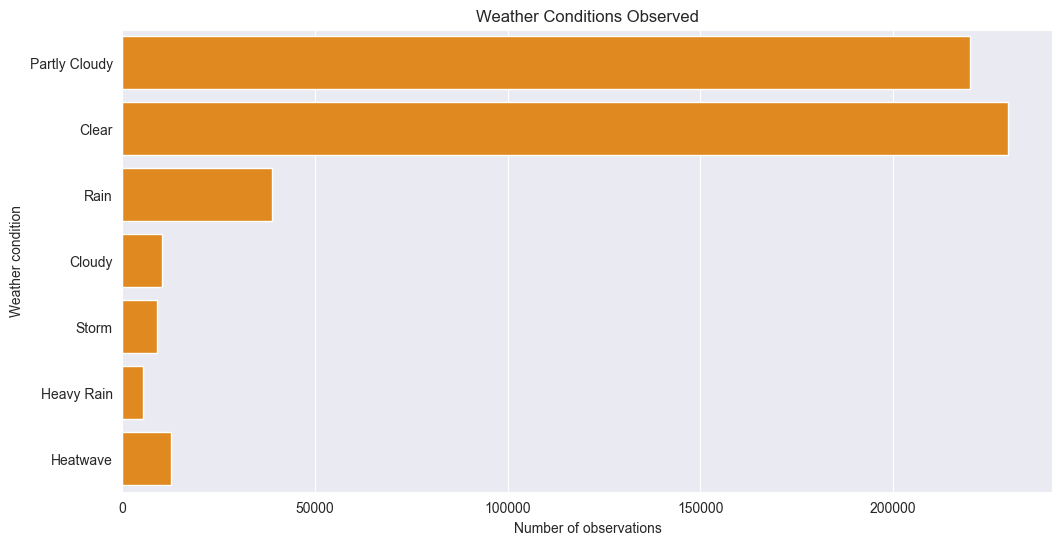

In [26]:
sns.countplot(df, y='weather_condition', color='darkorange')
plt.title('Weather Conditions Observed')
plt.xlabel('Number of observations')
plt.ylabel('Weather condition')

plt.show()

## Weather flags by district

In [27]:
districts = pd.read_csv('districts.csv')

districts_weather = districts.merge(df, on='district_id')

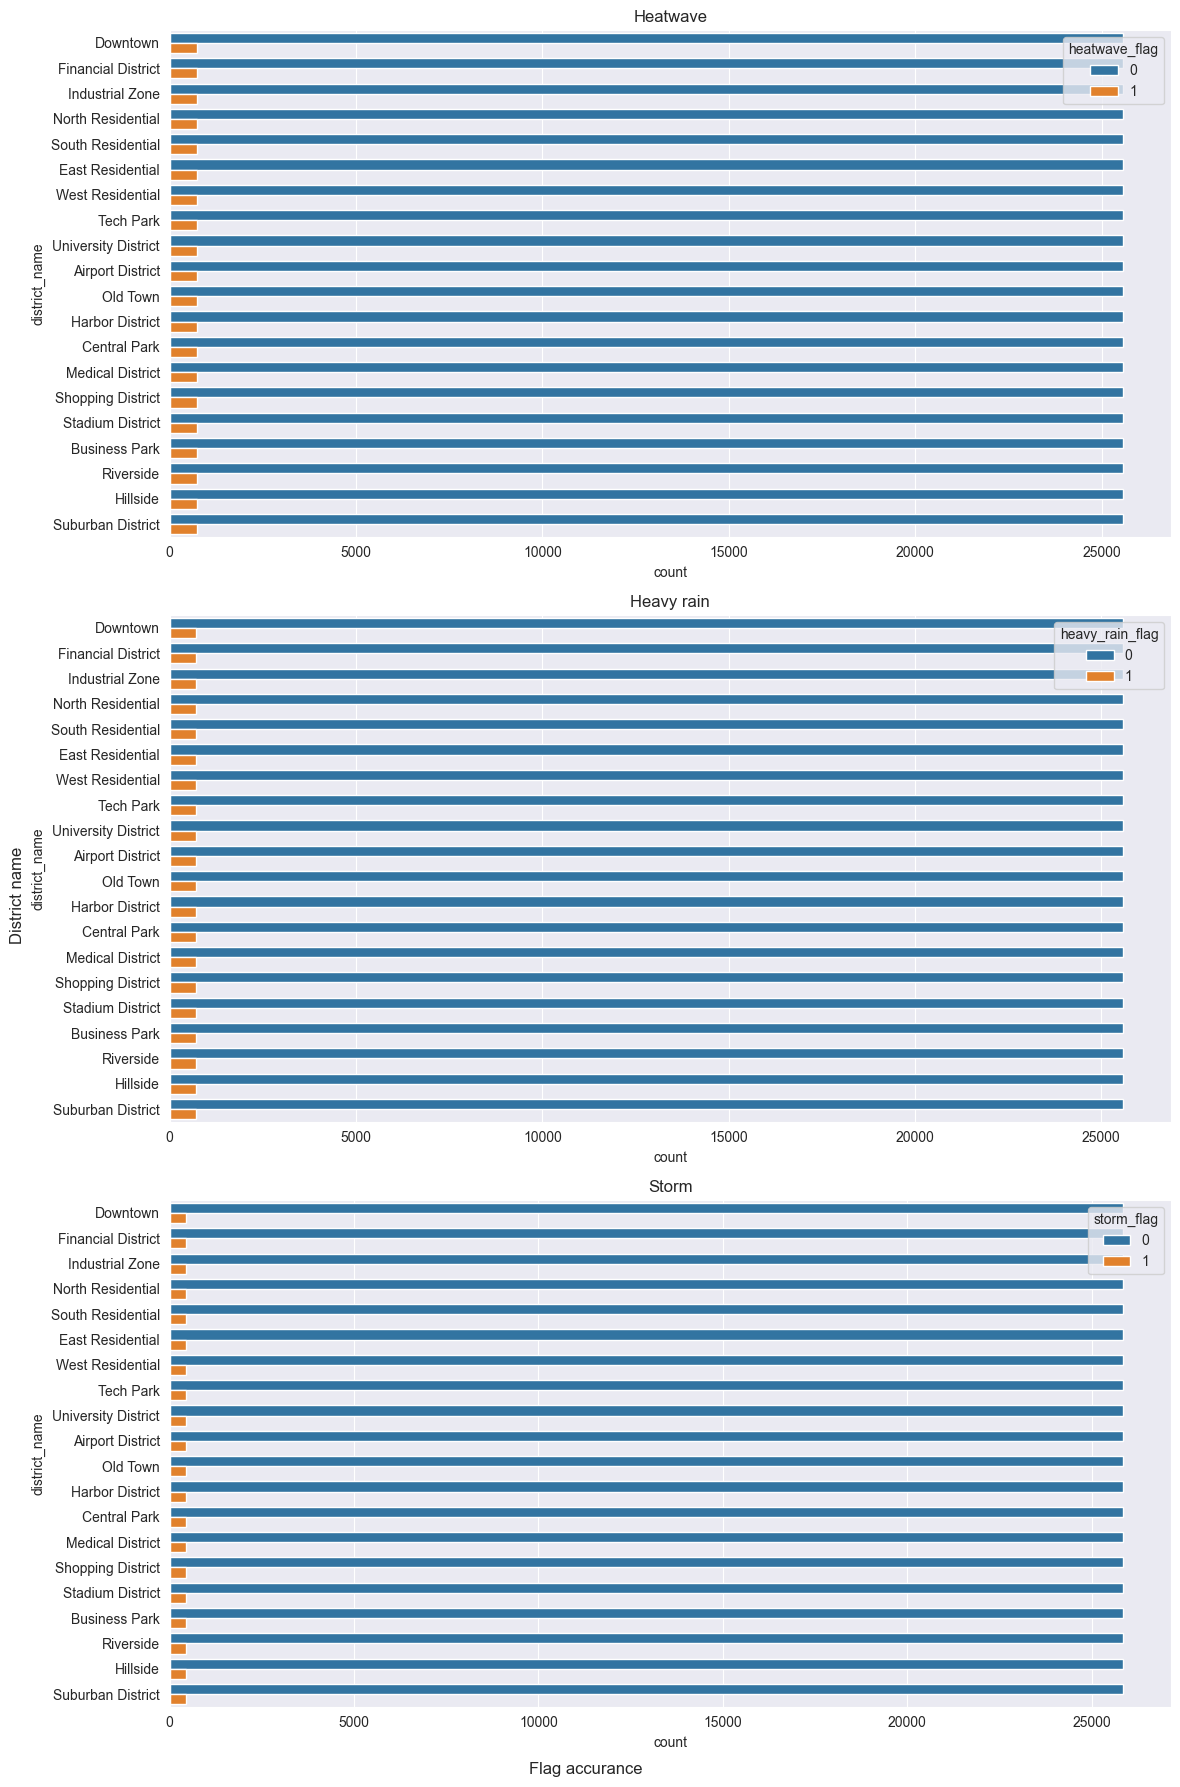

In [28]:
fig, ax = plt.subplots(3,1, figsize=(12, 18))

sns.countplot(districts_weather, y='district_name', hue='heatwave_flag', ax=ax[0])
sns.countplot(districts_weather, y='district_name', hue='heavy_rain_flag', ax=ax[1])
sns.countplot(districts_weather, y='district_name', hue='storm_flag', ax=ax[2])

ax[0].set_title('Heatwave')
ax[1].set_title('Heavy rain')
ax[2].set_title('Storm')

fig.supxlabel('Flag accurance')
fig.supylabel('District name')


plt.tight_layout()
plt.show()

## District climate profile

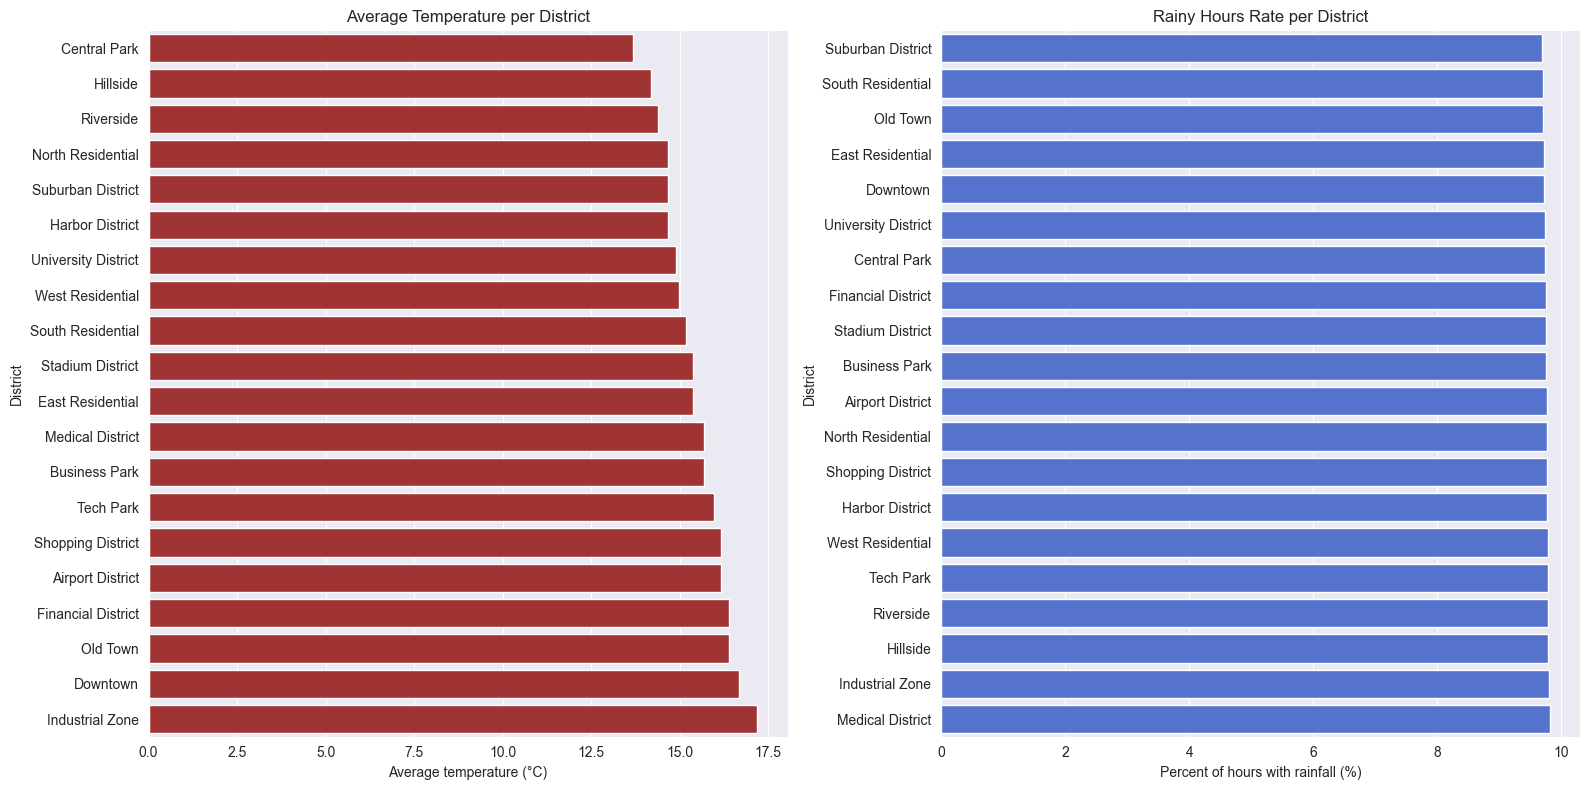

In [29]:
district_climate = districts_weather.groupby('district_name').agg(
    average_temperature=('temperature_c', 'mean'),
    rain_hour_rate=('rainfall_mm', lambda x: (x > 0).mean() * 100)
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(16, 8))

sns.barplot(district_climate.sort_values('average_temperature'), x='average_temperature', y='district_name', color='firebrick', ax=ax[0])
ax[0].set_title('Average Temperature per District')
ax[0].set_xlabel('Average temperature (°C)')
ax[0].set_ylabel('District')

sns.barplot(district_climate.sort_values('rain_hour_rate'), x='rain_hour_rate', y='district_name', color='royalblue', ax=ax[1])
ax[1].set_title('Rainy Hours Rate per District')
ax[1].set_xlabel('Percent of hours with rainfall (%)')
ax[1].set_ylabel('District')

plt.tight_layout()
plt.show()

# Data Cleaning

## Handling Nulls

In [30]:
cleaned_weather = df
cleaned_weather.ffill(inplace=True)
cleaned_weather.bfill(inplace=True)

,timestamp,district_id,temperature_c,feels_like_c,humidity_percent,rainfall_mm,wind_speed_kmh,cloud_cover_percent,weather_condition,heatwave_flag,heavy_rain_flag,storm_flag,sensor_status
0,2023-01-01 00:00:00,D01,-2.114558,-1.269328,64.790494,0.000000,2.755095,46.435298,Partly Cloudy,0,0,0,Normal
1,2023-01-01 01:00:00,D01,-1.071947,-0.618360,53.497799,0.000000,2.819884,0.000000,Clear,0,0,0,Normal
2,2023-01-01 02:00:00,D01,1.417415,0.012752,61.348556,0.000000,8.009989,31.153514,Partly Cloudy,0,0,0,Normal
3,2023-01-01 03:00:00,D01,0.118787,1.425774,65.823608,0.000000,7.983536,17.997245,Clear,0,0,0,Normal
4,2023-01-01 04:00:00,D01,3.300550,2.168793,40.948678,0.000000,13.769042,37.010263,Partly Cloudy,0,0,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
526075,2025-12-31 19:00:00,D20,3.404984,2.567980,75.129534,0.000000,11.408312,49.728874,Partly Cloudy,0,0,0,Normal
526076,2025-12-31 20:00:00,D20,2.557344,2.617756,45.813378,0.000000,7.446961,33.607246,Partly Cloudy,0,0,0,Normal
526077,2025-12-31 21:00:00,D20,-2.209800,-1.976816,61.402841,0.000000,8.485763,43.804237,Partly Cloudy,0,0,0,Normal
526078,2025-12-31 22:00:00,D20,-1.714643,-0.450025,41.643864,0.000000,5.531341,14.932425,Clear,0,0,0,Normal


In [31]:
cleaned_weather.to_csv('data/cleaned_weather.csv', index=False)